<a href="https://colab.research.google.com/github/vijaygururaj1805-ui/AI-Based-Road-Network-Pathfinding-System-UMN/blob/main/AI_Based_Road_Network_Pathfinding_System_UMN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# OSMnx lets us download real map/path data from OpenStreetMap.

!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 4.2 MB/s eta 0:00:00


In [ ]:
# Libraries we used in this project.

import osmnx as ox
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

import heapq
import math
import time
from collections import Counter

import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import textwrap

Map graph nodes: 12143
Map graph edges: 32636
Algorithm graph nodes: 12143
Algorithm graph edges: 32175


(<Figure size 1600x1000 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

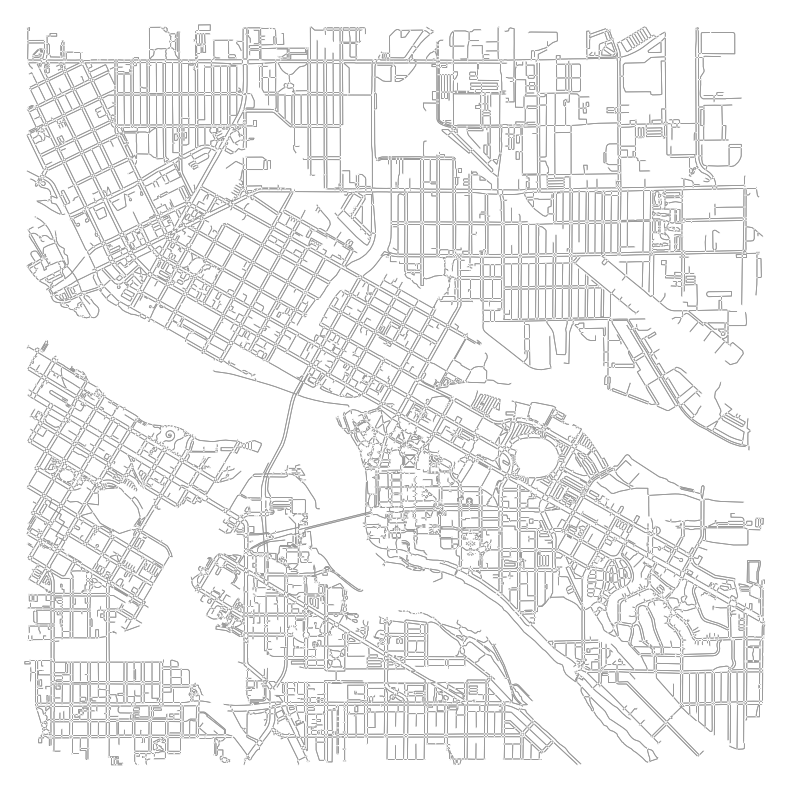

In [ ]:
# We are using a real walkable network around the University of Minnesota Twin Cities.
# network_type="walk" includes sidewalks, paths, pedestrian routes, and walkable roads.

umnCenter = (44.98000, -93.23540)  # near Dinkytown

# G_map is the original OSMnx graph.
# We keep this version for plotting maps.
G_map = ox.graph_from_point(
    umnCenter,
    dist=2300,
    network_type="walk",
    simplify=True
)

# Add distance values to each path/road segment.
# The distances are stored in meters.
G_map = ox.distance.add_edge_lengths(G_map)

# G is the simplified graph used for algorithms.
# This removes duplicate edges between the same two nodes and keeps the shortest edge.
G = ox.convert.to_digraph(G_map, weight="length")

print("Map graph nodes:", len(G_map.nodes))
print("Map graph edges:", len(G_map.edges))
print("Algorithm graph nodes:", len(G.nodes))
print("Algorithm graph edges:", len(G.edges))

# Show the basic walkable campus network.
ox.plot_graph(
    G_map,
    node_size=1,
    edge_linewidth=0.6,
    bgcolor="white",
    show=False,
    close=False,
    figsize=(16, 10)
)

In [ ]:
# These are approximate coordinates for major UMN Twin Cities landmarks.
#
# Format:
# "Landmark Name": (latitude, longitude)

umnLandmarks = {
    # East Bank / main campus
    "Coffman Memorial Union": (44.97399, -93.22773),
    "Northrop": (44.97613, -93.23535),
    "Walter Library": (44.97643, -93.23416),
    "Keller Hall": (44.97530, -93.23260),
    "Lind Hall": (44.97600, -93.23210),
    "Tate Hall": (44.97720, -93.23420),
    "Smith Hall": (44.97670, -93.23500),
    "Appleby Hall": (44.97470, -93.23430),
    "Bruininks Hall": (44.97490, -93.23640),
    "Morrill Hall": (44.97450, -93.23540),
    "Vincent Hall": (44.97490, -93.23380),
    "Ford Hall": (44.97590, -93.23490),
    "Pillsbury Hall": (44.97720, -93.23620),
    "Folwell Hall": (44.97740, -93.23570),

    # Science / engineering / health areas
    "Shepherd Laboratories": (44.97620, -93.23150),
    "Mechanical Engineering": (44.97570, -93.23110),
    "Amundson Hall": (44.97480, -93.23170),
    "Akerman Hall": (44.97660, -93.23220),
    "Civil Engineering Building": (44.97680, -93.23120),
    "Mayo Building": (44.97280, -93.23120),
    "Moos Tower": (44.97250, -93.23170),
    "Health Sciences Education Center": (44.97210, -93.23200),

    # Community / student spaces
    "Weisman Art Museum": (44.97320, -93.23710),
    "McNamara Alumni Center": (44.97790, -93.22770),
    "Recreation and Wellness Center": (44.97640, -93.23010),
    "Stadium Village Station": (44.97510, -93.22460),
    "Graduate Hotel / Stadium Village": (44.97530, -93.22570),

    # Athletics / public event spaces
    "Huntington Bank Stadium": (44.97652, -93.22467),
    "Williams Arena": (44.97670, -93.22870),
    "Mariucci Arena": (44.97820, -93.22980),
    "Ridder Arena": (44.97890, -93.22890),
    "Bierman Field Athletic Building": (44.98000, -93.22640),

    # River / bridges / outdoor paths
    "Washington Ave Bridge": (44.97310, -93.23970),
    "East River Parkway": (44.97220, -93.23880),
    "Bohemian Flats Park": (44.97020, -93.23860),
    "Bridge 9 / Dinkytown Greenway": (44.98120, -93.23850),
    "Dinkytown Greenway Trail": (44.98100, -93.23500),

    # West Bank
    "Anderson Hall": (44.97020, -93.24290),
    "Blegen Hall": (44.97010, -93.24390),
    "Wilson Library": (44.96980, -93.24480),
    "Carlson School of Management": (44.97020, -93.24670),
    "Humphrey School": (44.97040, -93.24790),
    "Rarig Center": (44.96890, -93.24170),
    "Ted Mann Concert Hall": (44.97090, -93.24040),
    "Social Sciences Building": (44.97070, -93.24330),
    "Law School": (44.97080, -93.24470),

    # Dinkytown / surrounding community areas
    "Dinkytown": (44.98000, -93.23540),
    "4th Street SE": (44.98030, -93.23330),
    "University Ave SE": (44.98200, -93.23200),
    "Oak Street SE": (44.97640, -93.22680),
    "Stone Arch Bridge Area": (44.98070, -93.25320),
    "Nicollet Island Park": (44.98710, -93.26230)

}

print("Number of landmarks:", len(umnLandmarks))

Number of landmarks: 52


In [ ]:
# Landmark groups for the map/key figure to make things easier to read.

landmarkGroups = {
    "East Bank / Main Campus": [
        "Coffman Memorial Union", "Northrop", "Walter Library", "Keller Hall",
        "Lind Hall", "Tate Hall", "Smith Hall", "Appleby Hall", "Bruininks Hall",
        "Morrill Hall", "Vincent Hall", "Ford Hall", "Pillsbury Hall", "Folwell Hall"
    ],
    "Science / Engineering / Health": [
        "Shepherd Laboratories", "Mechanical Engineering", "Amundson Hall",
        "Akerman Hall", "Civil Engineering Building", "Mayo Building",
        "Moos Tower", "Health Sciences Education Center"
    ],
    "Community / Student Spaces": [
        "Weisman Art Museum", "McNamara Alumni Center",
        "Recreation and Wellness Center", "Stadium Village Station",
        "Graduate Hotel / Stadium Village"
    ],
    "Athletics / Event Spaces": [
        "Huntington Bank Stadium", "Williams Arena", "Mariucci Arena",
        "Ridder Arena", "Bierman Field Athletic Building"
    ],
    "Outdoor / River / Bridges": [
        "Washington Ave Bridge", "East River Parkway", "Bohemian Flats Park",
        "Bridge 9 / Dinkytown Greenway", "Dinkytown Greenway Trail"
    ],
    "West Bank": [
        "Anderson Hall", "Blegen Hall", "Wilson Library",
        "Carlson School of Management", "Humphrey School", "Rarig Center",
        "Ted Mann Concert Hall", "Social Sciences Building", "Law School"
    ],
    "Dinkytown / Surrounding Area": [
        "Dinkytown", "4th Street SE", "University Ave SE",
        "Oak Street SE", "Stone Arch Bridge Area", "Nicollet Island Park"
    ]
}

groupColors = {
    "East Bank / Main Campus": "tab:blue",
    "Science / Engineering / Health": "tab:orange",
    "Community / Student Spaces": "tab:green",
    "Athletics / Event Spaces": "tab:red",
    "Outdoor / River / Bridges": "tab:purple",
    "West Bank": "tab:brown",
    "Dinkytown / Surrounding Area": "tab:pink"
}

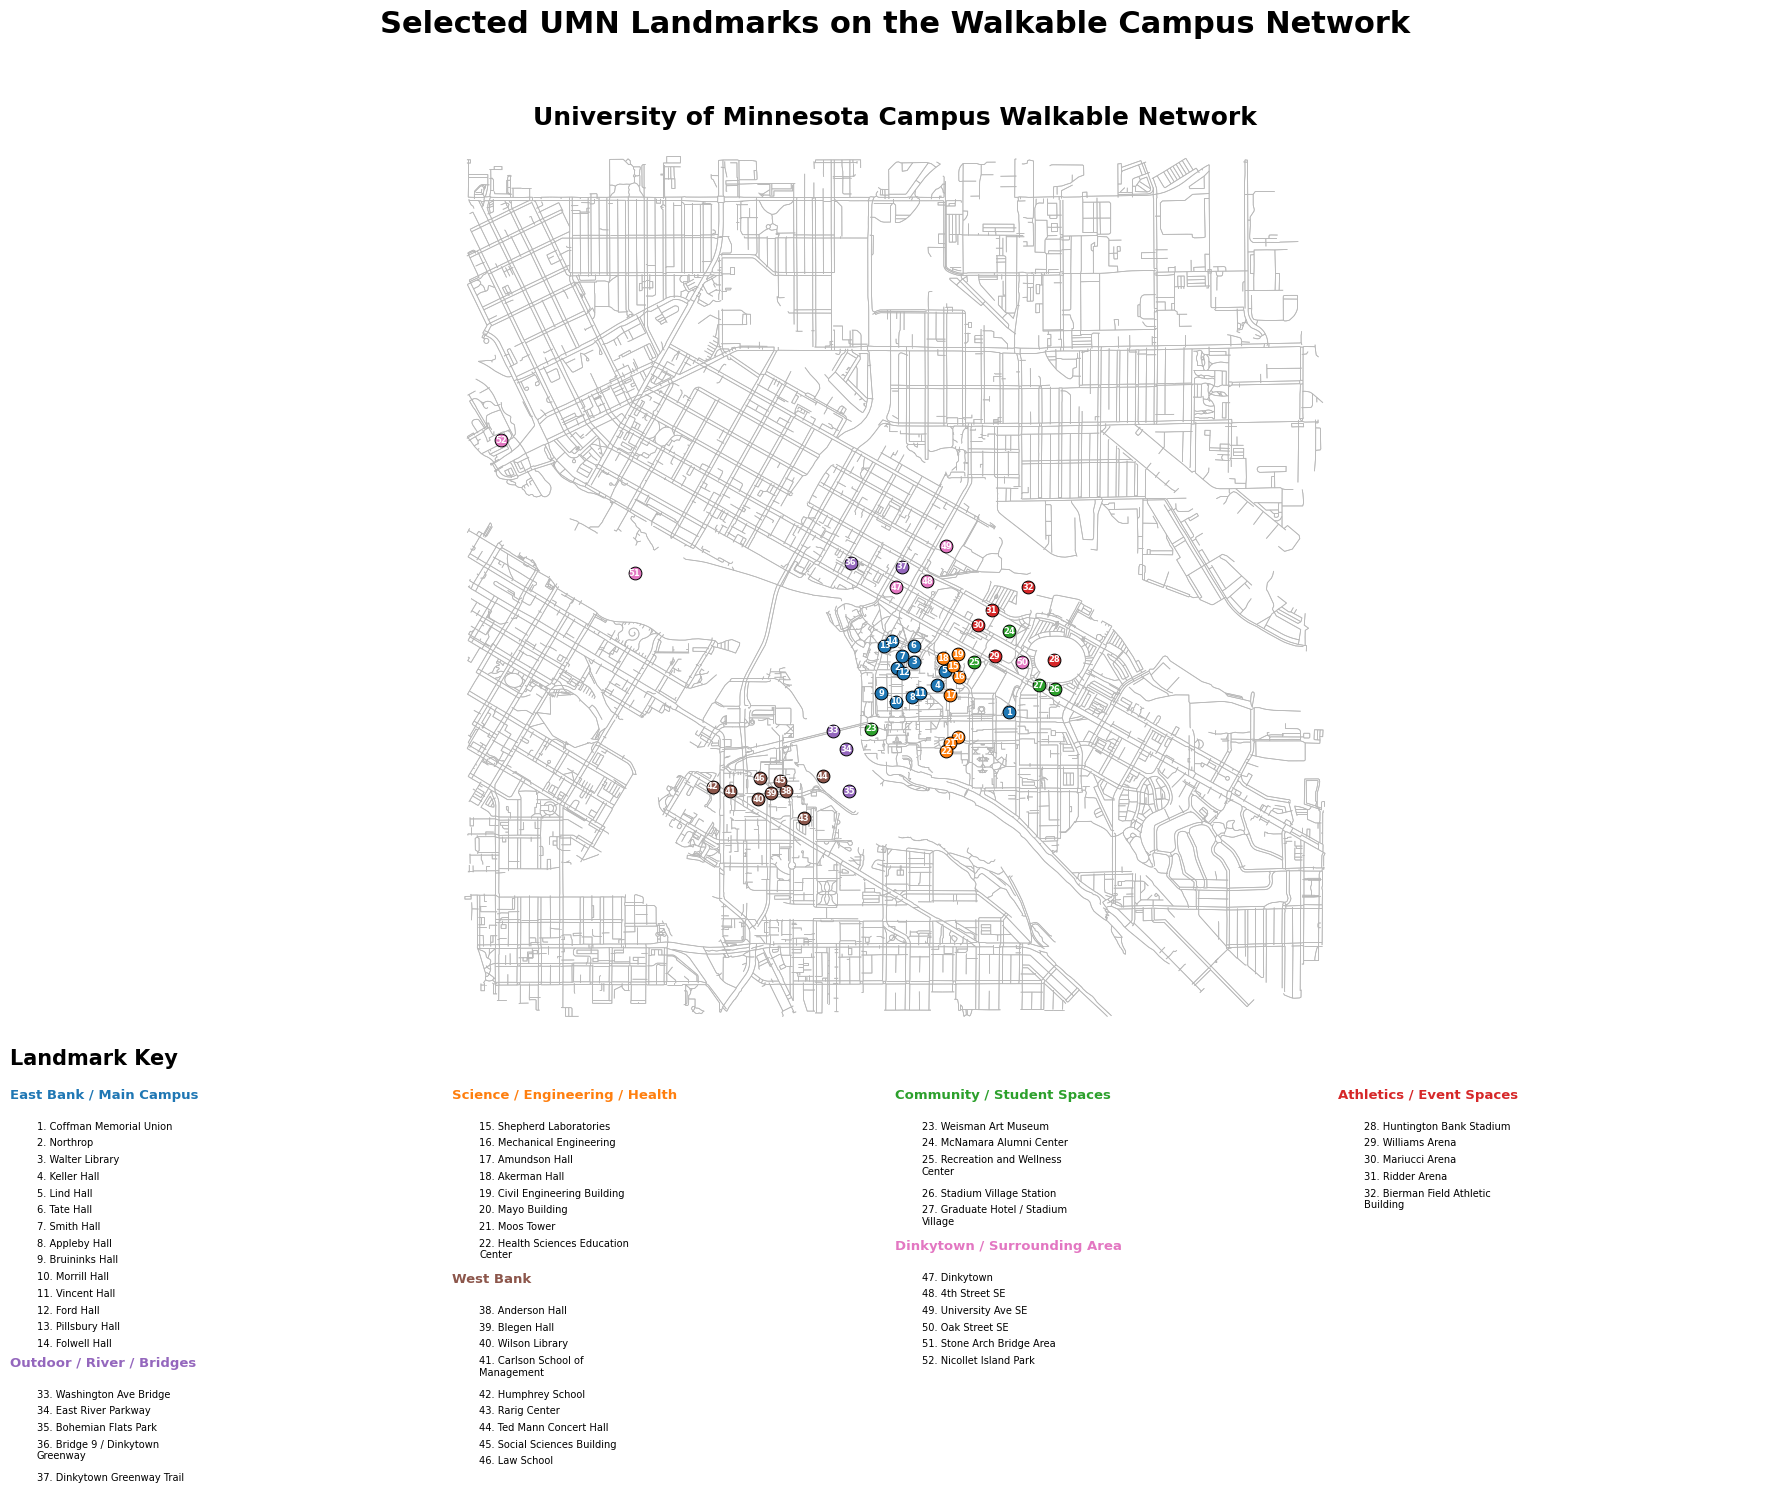

In [ ]:
# This map verifies that the graph covers the entire UMN campus area.
# The numbered key keeps the map readable while still showing all landmark names.

landmarkNumbers = {}
currentNumber = 1

for groupName, names in landmarkGroups.items():
    for name in names:
        if name in umnLandmarks:
            landmarkNumbers[name] = currentNumber
            currentNumber += 1

fig = plt.figure(figsize=(18, 15))
gs = GridSpec(2, 1, height_ratios=[3.2, 1.15], figure=fig)

axMap = fig.add_subplot(gs[0])
axKey = fig.add_subplot(gs[1])

# Plot campus network.
ox.plot_graph(
    G_map,
    ax=axMap,
    node_size=0,
    edge_linewidth=0.55,
    edge_color="#b8b8b8",
    bgcolor="white",
    show=False,
    close=False
)

# Plot numbered landmarks.
for groupName, names in landmarkGroups.items():
    for name in names:
        if name not in umnLandmarks:
            continue

        lat, lon = umnLandmarks[name]
        number = landmarkNumbers[name]

        axMap.scatter(
            lon,
            lat,
            s=85,
            color=groupColors[groupName],
            edgecolor="black",
            linewidth=0.7,
            zorder=5
        )

        axMap.text(
            lon,
            lat,
            str(number),
            fontsize=6,
            ha="center",
            va="center",
            color="white",
            weight="bold",
            zorder=6
        )

axMap.set_title("University of Minnesota Campus Walkable Network", fontsize=18, weight="bold", pad=10)

# Build compact grouped key underneath.
axKey.axis("off")
axKey.set_title("Landmark Key", fontsize=15, weight="bold", loc="left", pad=6)

columns = list(landmarkGroups.items())
numCols = 4
colWidth = 1 / numCols

for colIndex in range(numCols):
    x = colIndex * colWidth
    y = 0.92

    # Spread groups across 4 columns.
    groupSlice = columns[colIndex::numCols]

    for groupName, names in groupSlice:
        axKey.text(
            x,
            y,
            groupName,
            fontsize=9.5,
            weight="bold",
            color=groupColors[groupName],
            transform=axKey.transAxes
        )
        y -= 0.07

        for name in names:
            if name not in landmarkNumbers:
                continue

            labelText = f"{landmarkNumbers[name]}. {name}"
            wrapped = textwrap.fill(labelText, width=30)

            axKey.text(
                x + 0.015,
                y,
                wrapped,
                fontsize=7.1,
                transform=axKey.transAxes,
                va="top"
            )

            y -= 0.052 * (wrapped.count("\n") + 1)

        y -= 0.035

plt.suptitle(
    "Selected UMN Landmarks on the Walkable Campus Network",
    fontsize=22,
    weight="bold",
    y=0.985
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("umn_landmark_network.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# These helper functions keep the algorithm code cleaner.

def getCoords(node):
    # Return latitude and longitude for a graph node.
    return G.nodes[node]["y"], G.nodes[node]["x"]


def euclideanHeuristic(currentNode, goalNode):
    # Straight-line distance used by A*.
    lat1, lon1 = getCoords(currentNode)
    lat2, lon2 = getCoords(goalNode)
    return ox.distance.great_circle(lat1, lon1, lat2, lon2)


def pathDistance(path):
    # NetworkX calculates the total length of a path for us.
    return nx.path_weight(G, path, weight="length")

In [ ]:
# These functions estimate route complexity by counting turns.
# We ignore small bends under 30 degrees as they aren't full direction changes.

def turnDirection(previousNode, currentNode, nextNode):
    lat1, lon1 = getCoords(previousNode)
    lat2, lon2 = getCoords(currentNode)
    lat3, lon3 = getCoords(nextNode)

    # Treat longitude as x and latitude as y.
    x1, y1 = lon1, lat1
    x2, y2 = lon2, lat2
    x3, y3 = lon3, lat3

    vector1 = (x2 - x1, y2 - y1)
    vector2 = (x3 - x2, y3 - y2)

    dotProduct = vector1[0] * vector2[0] + vector1[1] * vector2[1]
    length1 = math.sqrt(vector1[0] ** 2 + vector1[1] ** 2)
    length2 = math.sqrt(vector2[0] ** 2 + vector2[1] ** 2)

    if length1 == 0 or length2 == 0:
        return "straight"

    cosineValue = dotProduct / (length1 * length2)
    cosineValue = max(-1, min(1, cosineValue))

    angle = math.degrees(math.acos(cosineValue))

    if angle < 30:
        return "straight"

    crossProduct = vector1[0] * vector2[1] - vector1[1] * vector2[0]

    if crossProduct > 0:
        return "left"
    else:
        return "right"


def countTurns(path):
    totalTurns = 0
    leftTurns = 0
    rightTurns = 0

    for i in range(1, len(path) - 1):
        direction = turnDirection(path[i - 1], path[i], path[i + 1])

        if direction == "left":
            totalTurns += 1
            leftTurns += 1
        elif direction == "right":
            totalTurns += 1
            rightTurns += 1

    return totalTurns, leftTurns, rightTurns

In [ ]:
# These penalties make the custom A* prefer simpler routes.
# Since this is a walkable network, this is a route-complexity penalty.

leftTurnPenalty = 50
rightTurnPenalty = 20


def getTurnPenalty(previousNode, currentNode, nextNode):
    # There is no turn penalty on the first step.
    if previousNode is None:
        return 0

    direction = turnDirection(previousNode, currentNode, nextNode)

    if direction == "left":
        return leftTurnPenalty
    elif direction == "right":
        return rightTurnPenalty
    else:
        return 0


def realisticCost(path):
    # This cost combines distance and turn penalties.
    distance = pathDistance(path)
    totalTurns, leftTurns, rightTurns = countTurns(path)
    return distance + (leftTurns * leftTurnPenalty) + (rightTurns * rightTurnPenalty)


def turnPenaltyAStar(startNode, goalNode):
    # Custom A* that adds penalties for turns while searching.
    priorityQueue = []
    heapq.heappush(priorityQueue, (0, 0, None, startNode, [startNode]))

    bestCost = {}

    while priorityQueue:
        priority, costSoFar, previousNode, currentNode, path = heapq.heappop(priorityQueue)

        state = (previousNode, currentNode)

        if state in bestCost and costSoFar > bestCost[state]:
            continue

        if currentNode == goalNode:
            return path

        for nextNode in G.successors(currentNode):
            edgeLength = G[currentNode][nextNode].get("length", 1)
            turnPenalty = getTurnPenalty(previousNode, currentNode, nextNode)

            newCost = costSoFar + edgeLength + turnPenalty
            nextState = (currentNode, nextNode)

            if nextState not in bestCost or newCost < bestCost[nextState]:
                bestCost[nextState] = newCost
                priorityValue = newCost + euclideanHeuristic(nextNode, goalNode)

                heapq.heappush(
                    priorityQueue,
                    (priorityValue, newCost, currentNode, nextNode, path + [nextNode])
                )

    return None

In [ ]:
# Convert every landmark coordinate into the nearest graph node.

landmarkNodes = {}

for name, coords in umnLandmarks.items():
    lat, lon = coords
    landmarkNodes[name] = ox.distance.nearest_nodes(G, lon, lat)

numLandmarks = len(landmarkNodes)
numRoutePairs = numLandmarks * (numLandmarks - 1)

print("Number of landmarks:", numLandmarks)
print("Number of directed route pairs:", numRoutePairs)
print("Number of algorithm runs:", numRoutePairs * 3)

Number of landmarks: 52
Number of directed route pairs: 2652
Number of algorithm runs: 7956


In [ ]:
# Run Dijkstra, A* Euclidean, and Turn-Penalty A*
# from every landmark to every other landmark.
#
# savedPaths stores the actual paths so later cells do not need to recompute them.

def evaluateRoute(startName, goalName, algorithmName, path, runtime):
    totalTurns, leftTurns, rightTurns = countTurns(path)

    return {
        "Start": startName,
        "Goal": goalName,
        "Algorithm": algorithmName,
        "Runtime Seconds": runtime,
        "Path Distance Meters": pathDistance(path),
        "Realistic Cost": realisticCost(path),
        "Total Turns": totalTurns,
        "Left Turns": leftTurns,
        "Right Turns": rightTurns,
        "Path Nodes": len(path),
        "Path Found": True
    }


def failedRoute(startName, goalName, algorithmName):
    return {
        "Start": startName,
        "Goal": goalName,
        "Algorithm": algorithmName,
        "Path Found": False
    }


allPairsResults = []
savedPaths = {}

for startName, startNode in landmarkNodes.items():
    for goalName, goalNode in landmarkNodes.items():

        if startName == goalName:
            continue

        algorithms = [
            ("Dijkstra", lambda: nx.shortest_path(G, startNode, goalNode, weight="length", method="dijkstra")),
            ("A* Euclidean", lambda: nx.astar_path(G, startNode, goalNode, heuristic=euclideanHeuristic, weight="length")),
            ("Turn-Penalty A*", lambda: turnPenaltyAStar(startNode, goalNode))
        ]

        for algorithmName, algorithmFunction in algorithms:
            startTime = time.time()

            try:
                path = algorithmFunction()
                runtime = time.time() - startTime

                if path is None:
                    allPairsResults.append(failedRoute(startName, goalName, algorithmName))
                else:
                    savedPaths[(startName, goalName, algorithmName)] = path
                    allPairsResults.append(
                        evaluateRoute(startName, goalName, algorithmName, path, runtime)
                    )

            except nx.NetworkXNoPath:
                allPairsResults.append(failedRoute(startName, goalName, algorithmName))

    # This avoids printing every single route.
    print("Finished routes from:", startName)


allPairsDf = pd.DataFrame(allPairsResults)

validPairsDf = allPairsDf[allPairsDf["Path Found"] == True].copy()

validPairsDf["Runtime Seconds"] = validPairsDf["Runtime Seconds"].round(6)
validPairsDf["Path Distance Meters"] = validPairsDf["Path Distance Meters"].round(2)
validPairsDf["Realistic Cost"] = validPairsDf["Realistic Cost"].round(2)

print("Successful algorithm runs:", len(validPairsDf))
validPairsDf.head()

Finished routes from: Coffman Memorial Union
Finished routes from: Northrop
Finished routes from: Walter Library
Finished routes from: Keller Hall
Finished routes from: Lind Hall
Finished routes from: Tate Hall
Finished routes from: Smith Hall
Finished routes from: Appleby Hall
Finished routes from: Bruininks Hall
Finished routes from: Morrill Hall
Finished routes from: Vincent Hall
Finished routes from: Ford Hall
Finished routes from: Pillsbury Hall
Finished routes from: Folwell Hall
Finished routes from: Shepherd Laboratories
Finished routes from: Mechanical Engineering
Finished routes from: Amundson Hall
Finished routes from: Akerman Hall
Finished routes from: Civil Engineering Building
Finished routes from: Mayo Building
Finished routes from: Moos Tower
Finished routes from: Health Sciences Education Center
Finished routes from: Weisman Art Museum
Finished routes from: McNamara Alumni Center
Finished routes from: Recreation and Wellness Center
Finished routes from: Stadium Village 

,Start,Goal,Algorithm,Runtime Seconds,Path Distance Meters,Realistic Cost,Total Turns,Left Turns,Right Turns,Path Nodes,Path Found
0,Coffman Memorial Union,Northrop,Dijkstra,0.004968,987.92,1217.92,7,3,4,25,True
1,Coffman Memorial Union,Northrop,A* Euclidean,0.013649,987.92,1217.92,7,3,4,25,True
2,Coffman Memorial Union,Northrop,Turn-Penalty A*,0.069908,991.57,1211.57,8,2,6,27,True
3,Coffman Memorial Union,Walter Library,Dijkstra,0.002987,777.40,1127.40,10,5,5,28,True
4,Coffman Memorial Union,Walter Library,A* Euclidean,0.005766,777.40,1127.40,10,5,5,28,True


In [ ]:
# This is the main table comparing the three algorithms.

summaryDf = validPairsDf.groupby("Algorithm").agg({
    "Runtime Seconds": "mean",
    "Path Distance Meters": "mean",
    "Realistic Cost": "mean",
    "Total Turns": "mean",
    "Left Turns": "mean",
    "Right Turns": "mean",
    "Path Nodes": "mean"
}).reset_index()

summaryDf

,Algorithm,Runtime Seconds,Path Distance Meters,Realistic Cost,Total Turns,Left Turns,Right Turns,Path Nodes
0,A* Euclidean,0.010345,1165.670528,1586.647149,12.027903,6.013952,6.013952,32.116139
1,Dijkstra,0.005905,1165.670528,1586.647149,12.027903,6.013952,6.013952,32.116139
2,Turn-Penalty A*,0.062845,1201.168627,1477.258371,8.370664,3.622549,4.748115,32.906486


In [ ]:
# Directly compare Dijkstra and Turn-Penalty A* on the same start-goal pairs.

comparisonRows = []

for startName in landmarkNodes:
    for goalName in landmarkNodes:

        if startName == goalName:
            continue

        dijkstraPath = savedPaths.get((startName, goalName, "Dijkstra"))
        turnPath = savedPaths.get((startName, goalName, "Turn-Penalty A*"))

        if dijkstraPath is None or turnPath is None:
            continue

        dijkstraTurns, dijkstraLeft, dijkstraRight = countTurns(dijkstraPath)
        turnTurns, turnLeft, turnRight = countTurns(turnPath)

        comparisonRows.append({
            "Start": startName,
            "Goal": goalName,
            "Same Path": dijkstraPath == turnPath,
            "Dijkstra Distance": pathDistance(dijkstraPath),
            "Turn A* Distance": pathDistance(turnPath),
            "Distance Change": pathDistance(turnPath) - pathDistance(dijkstraPath),
            "Dijkstra Cost": realisticCost(dijkstraPath),
            "Turn A* Cost": realisticCost(turnPath),
            "Cost Change": realisticCost(turnPath) - realisticCost(dijkstraPath),
            "Dijkstra Turns": dijkstraTurns,
            "Turn A* Turns": turnTurns,
            "Turn Change": turnTurns - dijkstraTurns
        })

comparisonDf = pd.DataFrame(comparisonRows)
changedRoutesDf = comparisonDf[comparisonDf["Same Path"] == False].copy()

print("Routes compared:", len(comparisonDf))
print("Routes changed by Turn-Penalty A*:", len(changedRoutesDf))
print("Percent changed:", round(100 * len(changedRoutesDf) / len(comparisonDf), 2), "%")

changedRoutesDf[[
    "Start", "Goal", "Distance Change", "Cost Change",
    "Dijkstra Turns", "Turn A* Turns", "Turn Change"
]].head(10)

Routes compared: 2652
Routes changed by Turn-Penalty A*: 2186
Percent changed: 82.43 %


,Start,Goal,Distance Change,Cost Change,Dijkstra Turns,Turn A* Turns,Turn Change
0,Coffman Memorial Union,Northrop,3.650491,-6.349509,7,8,1
1,Coffman Memorial Union,Walter Library,5.759194,-54.240806,10,10,0
2,Coffman Memorial Union,Keller Hall,3.650491,-6.349509,4,5,1
3,Coffman Memorial Union,Lind Hall,3.650491,-6.349509,6,7,1
4,Coffman Memorial Union,Tate Hall,5.759194,-54.240806,8,8,0
5,Coffman Memorial Union,Smith Hall,5.759194,-54.240806,11,11,0
6,Coffman Memorial Union,Appleby Hall,3.650491,-6.349509,3,4,1
7,Coffman Memorial Union,Bruininks Hall,3.650491,-6.349509,2,3,1
8,Coffman Memorial Union,Morrill Hall,31.219780,-18.780220,5,4,-1
9,Coffman Memorial Union,Vincent Hall,3.650491,-6.349509,2,3,1


In [ ]:
# This summarizes what happens when Turn-Penalty A* changes the route.

if len(changedRoutesDf) > 0:
    changedSummary = pd.DataFrame({
        "Metric": [
            "Average distance change",
            "Average realistic cost change",
            "Average turn change"
        ],
        "Value": [
            changedRoutesDf["Distance Change"].mean(),
            changedRoutesDf["Cost Change"].mean(),
            changedRoutesDf["Turn Change"].mean()
        ]
    })

    display(changedSummary)
else:
    print("Turn-Penalty A* did not change any routes with the current penalties.")

,Metric,Value
0,Average distance change,43.065272
1,Average realistic cost change,-132.707829
2,Average turn change,-4.436871


In [ ]:
# Use Dijkstra for route rankings so each route is only counted once.
# Very short routes under 50 meters are filtered out to avoid trivial neighboring landmarks.

dijkstraOnlyDf = validPairsDf[validPairsDf["Algorithm"] == "Dijkstra"].copy()
dijkstraRankDf = dijkstraOnlyDf[dijkstraOnlyDf["Path Distance Meters"] > 50].copy()

shortestRoutes = dijkstraRankDf.sort_values("Path Distance Meters").head(10)
longestRoutes = dijkstraRankDf.sort_values("Path Distance Meters", ascending=False).head(10)
mostComplexRoutes = dijkstraRankDf.sort_values("Realistic Cost", ascending=False).head(10)

print("Shortest non-trivial routes:")
display(shortestRoutes[[
    "Start", "Goal", "Path Distance Meters",
    "Total Turns", "Left Turns", "Right Turns", "Realistic Cost"
]])

print("Longest routes:")
display(longestRoutes[[
    "Start", "Goal", "Path Distance Meters",
    "Total Turns", "Left Turns", "Right Turns", "Realistic Cost"
]])

print("Most complex routes:")
display(mostComplexRoutes[[
    "Start", "Goal", "Realistic Cost", "Path Distance Meters",
    "Total Turns", "Left Turns", "Right Turns"
]])

Shortest non-trivial routes:


,Start,Goal,Path Distance Meters,Total Turns,Left Turns,Right Turns,Realistic Cost
2805,Civil Engineering Building,Akerman Hall,54.17,2,1,1,124.17
2652,Akerman Hall,Civil Engineering Building,54.17,2,1,1,124.17
924,Smith Hall,Walter Library,57.20,0,0,0,57.20
321,Walter Library,Smith Hall,57.20,0,0,0,57.20
2154,Shepherd Laboratories,Lind Hall,59.43,3,2,1,179.43
651,Lind Hall,Shepherd Laboratories,59.43,3,1,2,149.43
663,Lind Hall,Civil Engineering Building,63.87,2,1,1,133.87
2766,Civil Engineering Building,Lind Hall,63.87,2,1,1,133.87
6681,Ted Mann Concert Hall,Bohemian Flats Park,73.85,0,0,0,73.85
5328,Bohemian Flats Park,Ted Mann Concert Hall,73.85,0,0,0,73.85


Longest routes:


,Start,Goal,Path Distance Meters,Total Turns,Left Turns,Right Turns,Realistic Cost
7866,Nicollet Island Park,Health Sciences Education Center,3834.58,31,15,16,4904.58
3363,Health Sciences Education Center,Nicollet Island Park,3834.58,31,16,15,4934.58
7929,Nicollet Island Park,Rarig Center,3814.12,25,14,11,4734.12
6576,Rarig Center,Nicollet Island Park,3814.12,25,11,14,4644.12
7905,Nicollet Island Park,Bohemian Flats Park,3805.00,20,11,9,4535.00
5352,Bohemian Flats Park,Nicollet Island Park,3805.00,20,9,11,4475.00
7932,Nicollet Island Park,Ted Mann Concert Hall,3731.15,20,11,9,4461.15
6729,Ted Mann Concert Hall,Nicollet Island Park,3731.15,20,9,11,4401.15
7896,Nicollet Island Park,Bierman Field Athletic Building,3723.69,17,10,7,4363.69
4893,Bierman Field Athletic Building,Nicollet Island Park,3723.69,17,7,10,4273.69


Most complex routes:


,Start,Goal,Realistic Cost,Path Distance Meters,Total Turns,Left Turns,Right Turns
3363,Health Sciences Education Center,Nicollet Island Park,4934.58,3834.58,31,16,15
7866,Nicollet Island Park,Health Sciences Education Center,4904.58,3834.58,31,15,16
7863,Nicollet Island Park,Moos Tower,4736.31,3706.31,29,15,14
7929,Nicollet Island Park,Rarig Center,4734.12,3814.12,25,14,11
3210,Moos Tower,Nicollet Island Park,4706.31,3706.31,29,14,15
5199,East River Parkway,Nicollet Island Park,4698.70,3598.70,31,16,15
7902,Nicollet Island Park,East River Parkway,4668.70,3598.70,31,15,16
6576,Rarig Center,Nicollet Island Park,4644.12,3814.12,25,11,14
7860,Nicollet Island Park,Mayo Building,4591.77,3611.77,28,14,14
3057,Mayo Building,Nicollet Island Park,4591.77,3611.77,28,14,14


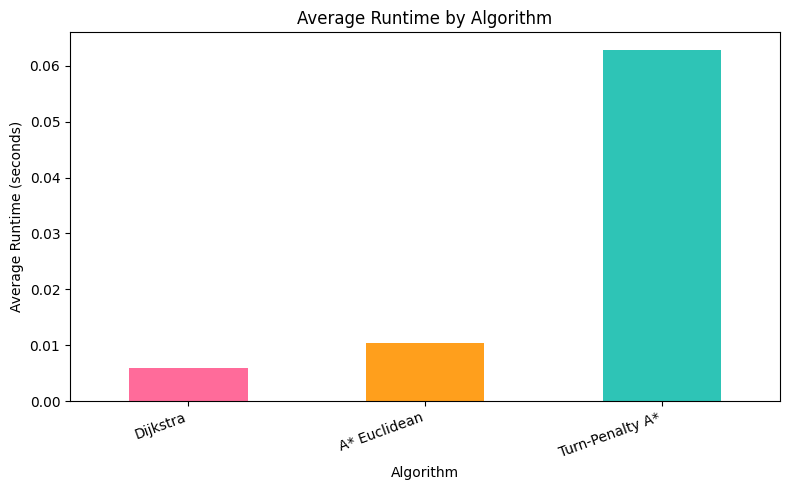

In [ ]:
# Average runtime by algorithm.

runtimeSummary = validPairsDf.groupby("Algorithm")["Runtime Seconds"].mean()

algorithmOrder = ["Dijkstra", "A* Euclidean", "Turn-Penalty A*"]
runtimeSummary = runtimeSummary.reindex(algorithmOrder)

barColors = ["#FF6B9A", "#FF9F1C", "#2EC4B6"]

plt.figure(figsize=(8, 5))
runtimeSummary.plot(kind="bar", color=barColors)

plt.ylabel("Average Runtime (seconds)")
plt.xlabel("Algorithm")
plt.title("Average Runtime by Algorithm")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.savefig("runtime_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

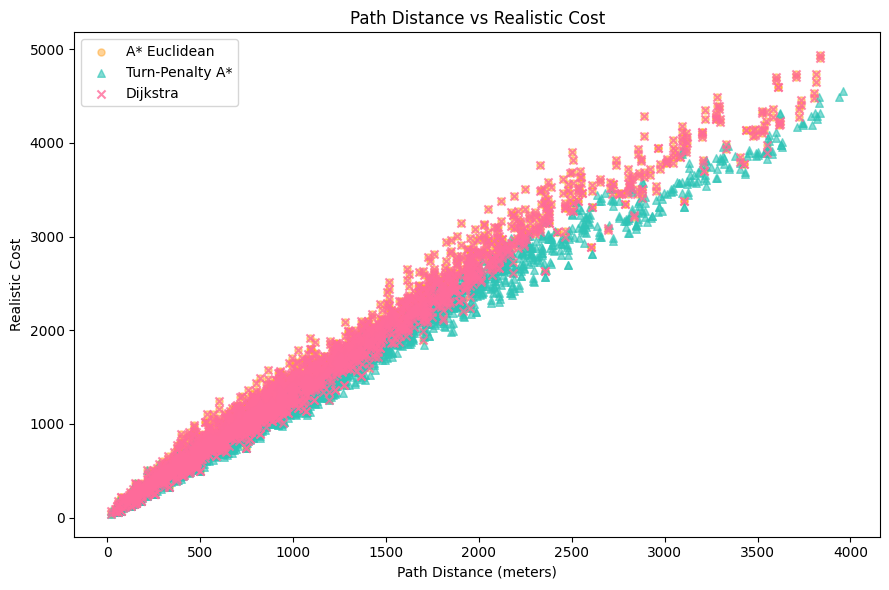

In [ ]:
# This compares normal distance with complexity-adjusted cost.

algorithmStyles = {
    "Dijkstra": {
        "color": "#FF6B9A",      # pink
        "marker": "x",
        "alpha": 0.80,
        "size": 34
    },
    "A* Euclidean": {
        "color": "#FF9F1C",      # orange
        "marker": "o",
        "alpha": 0.45,
        "size": 26
    },
    "Turn-Penalty A*": {
        "color": "#2EC4B6",      # turquoise
        "marker": "^",
        "alpha": 0.60,
        "size": 30
    }
}

plotOrder = ["A* Euclidean", "Turn-Penalty A*", "Dijkstra"]

plt.figure(figsize=(9, 6))

for algorithmName in plotOrder:
    tempDf = validPairsDf[validPairsDf["Algorithm"] == algorithmName]
    style = algorithmStyles[algorithmName]

    plt.scatter(
        tempDf["Path Distance Meters"],
        tempDf["Realistic Cost"],
        label=algorithmName,
        color=style["color"],
        marker=style["marker"],
        alpha=style["alpha"],
        s=style["size"]
    )

plt.xlabel("Path Distance (meters)")
plt.ylabel("Realistic Cost")
plt.title("Path Distance vs Realistic Cost")
plt.legend()

plt.tight_layout()
plt.savefig("distance_vs_realistic_cost.png", dpi=300, bbox_inches="tight")
plt.show()

,Start,Path Distance Meters,Realistic Cost,Total Turns
24,Lind Hall,818.939804,1151.292745,10.117647
9,Bruininks Hall,819.705882,1068.333333,7.196078
43,Tate Hall,823.792353,1163.204118,10.000000
2,Amundson Hall,827.439412,1188.027647,10.588235
28,Mechanical Engineering,832.908431,1118.006471,8.196078
46,Vincent Hall,833.725882,1125.686667,8.450980
39,Smith Hall,833.757647,1189.051765,10.176471
11,Civil Engineering Building,836.792941,1170.714510,9.490196
30,Morrill Hall,840.469020,1199.488627,10.215686
4,Appleby Hall,843.929804,1166.282745,9.294118


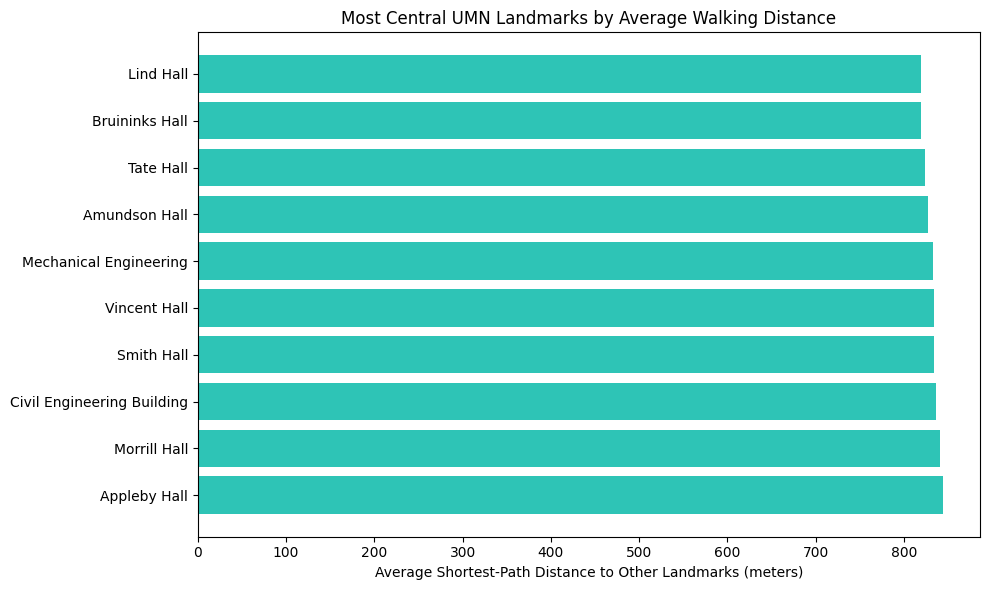

In [ ]:
# A landmark is more central if its average shortest-path distance
# to all other landmarks is lower.

centralityDf = dijkstraOnlyDf.groupby("Start").agg({
    "Path Distance Meters": "mean",
    "Realistic Cost": "mean",
    "Total Turns": "mean"
}).reset_index()

centralityDf = centralityDf.sort_values("Path Distance Meters")
topCentral = centralityDf.head(10)

display(topCentral)

plt.figure(figsize=(10, 6))
plt.barh(topCentral["Start"], topCentral["Path Distance Meters"], color="#2EC4B6")

plt.xlabel("Average Shortest-Path Distance to Other Landmarks (meters)")
plt.title("Most Central UMN Landmarks by Average Walking Distance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("central_landmarks.png", dpi=300, bbox_inches="tight")
plt.show()

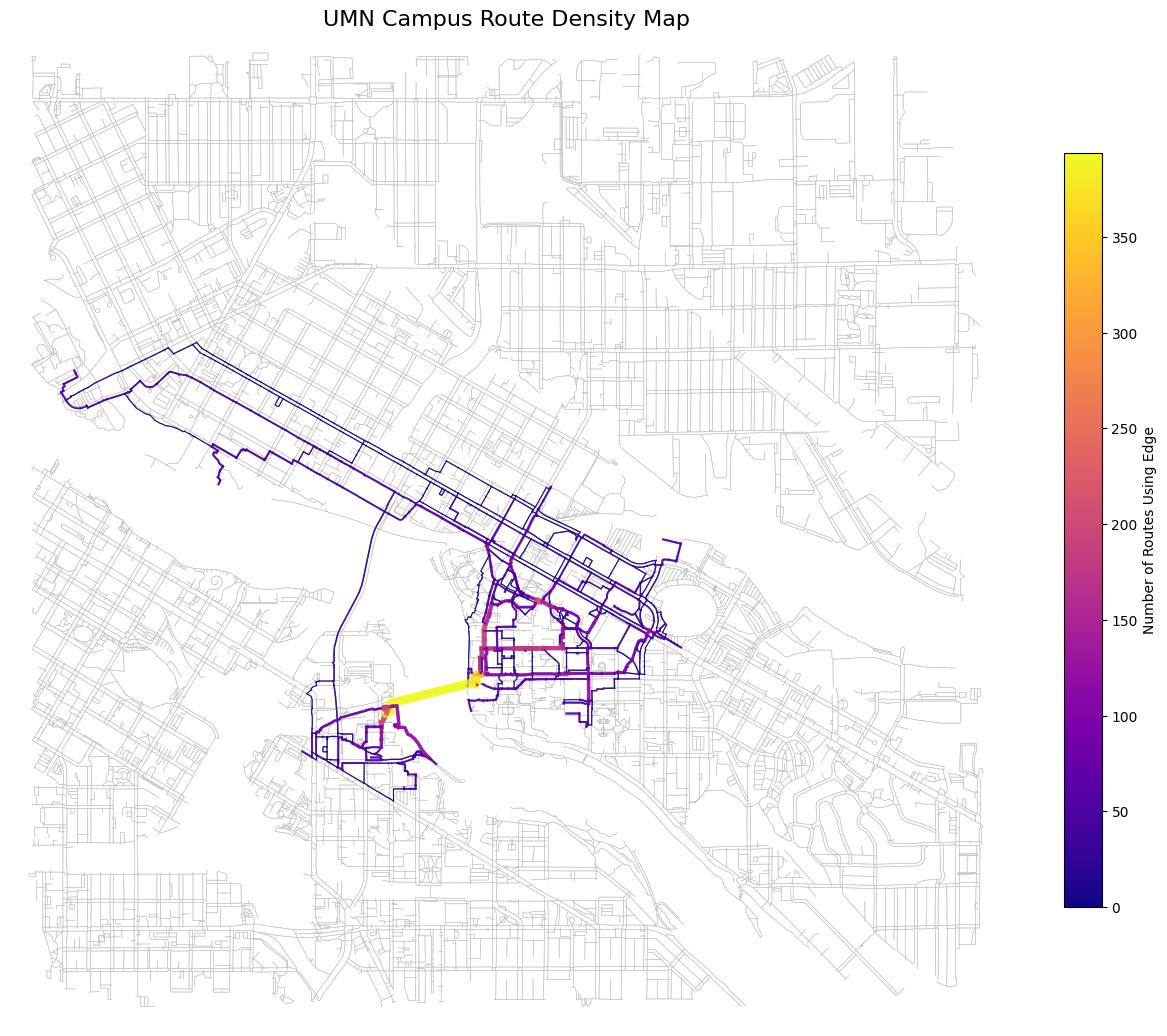

In [ ]:
# Route density map with full campus network visible underneath.
# Light gray = full walkable network
# Bright/thick lines = paths used often by Dijkstra shortest paths

edgeCounts = Counter()

for (startName, goalName, algorithmName), path in savedPaths.items():
    if algorithmName != "Dijkstra":
        continue

    for i in range(len(path) - 1):
        edgeCounts[(path[i], path[i + 1])] += 1

maxCount = max(edgeCounts.values())

colorMap = cm.plasma
normalizer = mcolors.Normalize(vmin=0, vmax=maxCount)

fig, ax = ox.plot_graph(
    G_map,
    node_size=0,
    edge_linewidth=0.35,
    edge_color="#bfbfbf",
    bgcolor="white",
    show=False,
    close=False,
    figsize=(16, 14)
)

# Overlay only the used route-density edges.
for u, v, key in G_map.edges(keys=True):
    count = edgeCounts.get((u, v), 0)

    if count > 0:
        edgeData = G_map.edges[u, v, key]

        if "geometry" in edgeData:
            xs, ys = edgeData["geometry"].xy
        else:
            xs = [G_map.nodes[u]["x"], G_map.nodes[v]["x"]]
            ys = [G_map.nodes[u]["y"], G_map.nodes[v]["y"]]

        ax.plot(
            xs,
            ys,
            color=colorMap(normalizer(count)),
            linewidth=0.7 + 5.5 * (count / maxCount),
            alpha=0.75,
            zorder=4
        )

plt.title("UMN Campus Route Density Map", fontsize=16)

sm = cm.ScalarMappable(cmap=colorMap, norm=normalizer)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, shrink=0.7)
cbar.set_label("Number of Routes Using Edge")

plt.savefig("route_density_map.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Find a good example route where Turn-Penalty A* changes the route.
# We choose the route with the biggest decrease in realistic cost.

if len(changedRoutesDf) > 0:
    bestExample = changedRoutesDf.sort_values("Cost Change").iloc[0]
    customStart = bestExample["Start"]
    customGoal = bestExample["Goal"]
else:
    customStart = "Nicollet Island Park"
    customGoal = "Rarig Center"

print("Example route:", customStart, "to", customGoal)

Example route: Rarig Center to Mariucci Arena


In [ ]:
# Compare the three algorithms on the selected example route.

dijkstraPath = savedPaths[(customStart, customGoal, "Dijkstra")]
astarPath = savedPaths[(customStart, customGoal, "A* Euclidean")]
turnPath = savedPaths[(customStart, customGoal, "Turn-Penalty A*")]

for name, path in [
    ("Dijkstra", dijkstraPath),
    ("A* Euclidean", astarPath),
    ("Turn-Penalty A*", turnPath)
]:
    totalTurns, leftTurns, rightTurns = countTurns(path)

    print(name)
    print("Distance:", round(pathDistance(path), 2), "meters")
    print("Realistic Cost:", round(realisticCost(path), 2))
    print("Total Turns:", totalTurns)
    print("Left Turns:", leftTurns)
    print("Right Turns:", rightTurns)
    print("Path Nodes:", len(path))
    print()

print("Dijkstra and A* same path:", dijkstraPath == astarPath)
print("Dijkstra and Turn-Penalty A* same path:", dijkstraPath == turnPath)

Dijkstra
Distance: 2329.58 meters
Realistic Cost: 3759.58
Total Turns: 37
Left Turns: 23
Right Turns: 14
Path Nodes: 67

A* Euclidean
Distance: 2329.58 meters
Realistic Cost: 3759.58
Total Turns: 37
Left Turns: 23
Right Turns: 14
Path Nodes: 67

Turn-Penalty A*
Distance: 2598.38 meters
Realistic Cost: 3138.38
Total Turns: 18
Left Turns: 6
Right Turns: 12
Path Nodes: 71

Dijkstra and A* same path: True
Dijkstra and Turn-Penalty A* same path: False


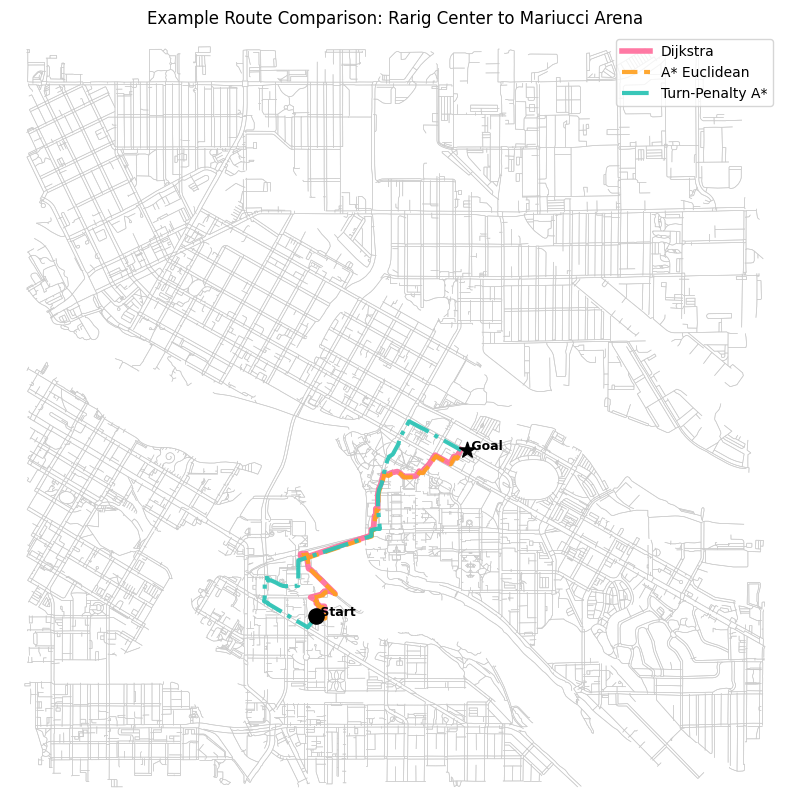

In [ ]:
# Plot all three example routes on one map.

fig, ax = ox.plot_graph(
    G_map,
    node_size=0,
    edge_linewidth=0.45,
    edge_color="#cccccc",
    bgcolor="white",
    show=False,
    close=False,
    figsize=(13, 10)
)

def getRouteCoords(path, xOffset=0, yOffset=0):
    # Convert a path into x/y coordinates for plotting.
    xValues = []
    yValues = []

    for node in path:
        xValues.append(G_map.nodes[node]["x"] + xOffset)
        yValues.append(G_map.nodes[node]["y"] + yOffset)

    return xValues, yValues


# Tiny offsets only for visualization.
# These do not change the actual route calculations.
dijkstraX, dijkstraY = getRouteCoords(dijkstraPath, xOffset=-0.00003, yOffset=0.00003)
astarX, astarY = getRouteCoords(astarPath, xOffset=0.00003, yOffset=-0.00003)
turnX, turnY = getRouteCoords(turnPath, xOffset=0, yOffset=0)

# Plot routes manually so we can control style better.
ax.plot(
    dijkstraX,
    dijkstraY,
    color="#FF6B9A",
    linewidth=4,
    linestyle="-",
    alpha=0.9,
    label="Dijkstra"
)

ax.plot(
    astarX,
    astarY,
    color="#FF9F1C",
    linewidth=3,
    linestyle="--",
    alpha=0.9,
    label="A* Euclidean"
)

ax.plot(
    turnX,
    turnY,
    color="#2EC4B6",
    linewidth=3,
    linestyle="-.",
    alpha=0.95,
    label="Turn-Penalty A*"
)

# Mark start and goal.
startLat, startLon = umnLandmarks[customStart]
goalLat, goalLon = umnLandmarks[customGoal]

ax.scatter(startLon, startLat, s=120, color="black", marker="o", zorder=6)
ax.scatter(goalLon, goalLat, s=140, color="black", marker="*", zorder=6)

ax.text(startLon, startLat, " Start", fontsize=9, weight="bold")
ax.text(goalLon, goalLat, " Goal", fontsize=9, weight="bold")

plt.legend()
plt.title("Example Route Comparison: " + customStart + " to " + customGoal)

plt.savefig("example_route_comparison.png", dpi=300, bbox_inches="tight")
plt.show()